# Chapter 37: Natural Monopoly, Regulation, and Public-Utility Pricing

This notebook reruns four worked examples from the chapter: peak-load pricing of shared capacity, a subadditivity test for natural monopoly, Ramsey fares against a uniform markup, and a price ceiling with its shortage and queue. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def plural(count, singular, plural_form=None):
    """'1 trip', '3 trips', '0 trips'. Count is printed as an integer when whole."""
    word = singular if count == 1 else (plural_form or singular + "s")
    shown = str(int(count)) if float(count).is_integer() else str(count)
    return f"{shown} {word}"


def peak_load(c, beta, a_off, a_peak, uniform=None):
    """peak-load-pricing with only the peak constraint binding: p_O = c, p_P = c + beta.

    Demands q_O = a_off - p_O and q_P = a_peak - p_P. Book (ch037): c = 20, beta = 40,
    intercepts 100 and 160 give p 20 and 60, q 80 and 100, K = 100, idle 20; uniform 40 gives
    q 60 and 120 and K = 120.
    """
    if uniform is None:
        p_o, p_p = c, c + beta
    else:
        p_o = p_p = uniform
    q_o, q_p = a_off - p_o, a_peak - p_p
    if uniform is None and q_o > q_p:
        raise ValueError("off-peak constraint binds; not modelled")
    K = max(q_o, q_p)
    return {"p_off": p_o, "p_peak": p_p, "q_off": q_o, "q_peak": q_p, "K": K, "idle": K - q_o}


def split_cost(tech, Q, m):
    """natural-monopoly-by-subadditivity: industry cost when m firms split Q equally.

    tech "linear": C(q) = 100 + 2q; "congestion": C(q) = 40 + q + 0.02 q^2.
    Book (ch037): linear 300 for one firm, 400 for two; congestion 340 and 2(140) = 280.
    """
    q = Q / m
    each = 100 + 2 * q if tech == "linear" else 40 + q + 0.02 * q * q
    return {"q": q, "each": each, "total": m * each}


def ramsey_two(target, q0, p0, eps_c, eps_l, scheme="ramsey"):
    """ramsey-boiteux-pricing, small-change approximation with equal initial prices and quantities.

    Markups sum to target / q0; Ramsey sets m_C / m_L = eps_L / eps_C. Lost trips
    |dq| = eps (m / p0) q0 and DWL = (1/2) m |dq|. Book (ch037): 0.72 and 0.18, 180 and 180,
    DWL 64.80 + 16.20 = 81; uniform 0.45 gives 112.5 and 450, 25.31 + 101.25 = 126.56.
    """
    total = target / q0
    if scheme == "ramsey":
        m_c = total * eps_l / (eps_c + eps_l)
        m_l = total - m_c
    else:
        m_c = m_l = total / 2
    dq_c, dq_l = eps_c * m_c / p0 * q0, eps_l * m_l / p0 * q0
    dwl_c, dwl_l = 0.5 * m_c * dq_c, 0.5 * m_l * dq_l
    return {"m_c": m_c, "m_l": m_l, "dq_c": dq_c, "dq_l": dq_l, "dwl_c": dwl_c, "dwl_l": dwl_l,
            "dwl": dwl_c + dwl_l}


def ceiling_market(ceiling, queue=0.0):
    """price-controls-rationing: Q_D = 120 - 2p, Q_S = 3p, ceiling and queue cost.

    Surplus to quantity Q is the integral of 60 - q/2 - q/3, that is 60 Q - (5/12) Q^2.
    Book (ch037): p* 24, Q* 72; ceiling 12 gives demand 96, supply 36, shortage 60, p_D 42,
    surplus 1,620 against 2,160, after a 300 queue cost 1,320.
    """
    p_star, q_star = 24.0, 72.0
    binding = ceiling < p_star
    p = ceiling if binding else p_star
    qd, qs = 120 - 2 * p, 3 * p
    traded = qs
    surplus = 60 * traded - 5 / 12 * traded ** 2
    queue_cost = queue if binding else 0.0
    return {"p_star": p_star, "q_star": q_star, "binding": binding, "price": p, "demand": qd, "supply": qs,
            "shortage": qd - qs, "wtp": 60 - traded / 2, "premium": 60 - traded / 2 - p, "surplus": surplus,
            "benchmark": 60 * q_star - 5 / 12 * q_star ** 2, "queue": queue_cost, "realized": surplus - queue_cost}


plt.rcParams.update(HOUSE_RC)


industrial = SimpleNamespace(peak_load=peak_load, split_cost=split_cost, ramsey_two=ramsey_two, ceiling_market=ceiling_market)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'peak-load-pricing': {'c': 20,
                       'beta': 40,
                       'a_off': 100,
                       'a_peak': 160,
                       'p_off': 20,
                       'p_peak': 60,
                       'q_off': 80,
                       'q_peak': 100,
                       'K': 100,
                       'idle': 20,
                       'uniform': 40,
                       'u_q_off': 60,
                       'u_q_peak': 120,
                       'u_K': 120},
 'natural-monopoly-by-subadditivity': {'Q': 100,
                                       'linear_one': 300,
                                       'linear_split': 400,
                                       'congestion_one': 340,
                                       'congestion_two': 280},
 'ramsey-boiteux-pricing': {'c': 2,
                            'q0': 1000,
                            'target': 900,
                            'eps_c': 0.5,
                            'eps_l': 2,
                            'm_c': 0.72,
                            'm_l': 0.18,
                            'dq_c': 180,
                            'dq_l': 180,
                            'dwl_c': 64.8,
                            'dwl_l': 16.2,
                            'dwl': 81,
                            'u_m': 0.45,
                            'u_dq_c': 112.5,
                            'u_dq_l': 450,
                            'u_dwl_c': 25.31,
                            'u_dwl_l': 101.25,
                            'u_dwl': 126.56},
 'price-controls-rationing': {'p_star': 24,
                              'q_star': 72,
                              'ceiling': 12,
                              'demand': 96,
                              'supply': 36,
                              'shortage': 60,
                              'wtp': 42,
                              'premium': 30,
                              'surplus': 1620,
                              'benchmark': 2160,
                              'lost': 540,
                              'queue': 300,
                              'realized': 1320,
                              'below': 840,
                              'ceiling_high': 30},
 'constructed': {'peak-load-pricing': {'beta': [20, 60]},
                 'natural-monopoly-by-subadditivity': {'firms': [4]},
                 'ramsey-boiteux-pricing': {'eps_c': [1]},
                 'price-controls-rationing': {'ceiling': [18, 24], 'queue_at_18': 300}}}


def peak_picture(capcost=40, tariff="efficient"):
    bv = BV["peak-load-pricing"]
    uni = None if tariff == "efficient" else bv["uniform"]
    r = industrial.peak_load(bv["c"], capcost, bv["a_off"], bv["a_peak"], uniform=uni)
    fig, ax = new_figure()
    qs = np.linspace(0, 160, 100)
    ax.plot(qs, np.clip(100 - qs, 0, None), color=PALETTE["teal"], linewidth=2.2, label="off-peak p = 100 - q")
    ax.plot(qs, 160 - qs, color=PALETTE["navy"], linewidth=2.2, label="peak p = 160 - q")
    if r["idle"] > 0:
        ax.axvspan(r["q_off"], r["K"], color=PALETTE["gold"], alpha=0.22)
        label(ax, (r["q_off"] + r["K"]) / 2, 108, f"idle off-peak {num(r['idle'], 0)}", col="ink", dx=0, dy=0,
              ha="center")
    vline(ax, r["K"], f"capacity K = {num(r['K'], 0)}", col="terracotta", y_frac=0.97, ha="right")
    mark(ax, r["q_off"], r["p_off"], f"off-peak ({num(r['q_off'], 0)}, {num(r['p_off'], 0)})", col="teal", dx=8,
         dy=6)
    mark(ax, r["q_peak"], r["p_peak"], f"peak ({num(r['q_peak'], 0)}, {num(r['p_peak'], 0)})", col="navy", dx=8, dy=6)
    ax.set_xlim(0, 165)
    ax.set_ylim(0, 170)
    ax.legend(loc="lower left", frameon=False)
    ax.set_xlabel("Quantity q")
    ax.set_ylabel("Price p")
    metrics = {"Off-peak price p_O": num(r["p_off"], 0), "Peak price p_P": num(r["p_peak"], 0),
               "Off-peak quantity q_O": num(r["q_off"], 0), "Peak quantity q_P": num(r["q_peak"], 0),
               "Capacity K": num(r["K"], 0), "Idle off-peak capacity": num(r["idle"], 0)}
    if uni is None:
        idle = ("so another off-peak unit triggers no investment" if r["idle"] > 0 else
                "so the off-peak demand just reaches capacity and both periods use all of it")
        interp = (f"Only the peak constraint binds, so off-peak users pay operating cost, p_O = 20, and peak users also "
                  f"pay for capacity, p_P = 20 + {capcost} = {num(r['p_peak'], 0)}. Then q_O = 100 - 20 = "
                  f"{num(r['q_off'], 0)} and q_P = 160 - {num(r['p_peak'], 0)} = {num(r['q_peak'], 0)}, so K = "
                  f"{num(r['K'], 0)}. Idle off-peak capacity is {num(r['K'], 0)} - {num(r['q_off'], 0)} = "
                  f"{num(r['idle'], 0)}, {idle}.")
        steps = ["p_O = 20", f"p_P = 20 + {capcost} = {num(r['p_peak'], 0)}", f"q_O = 100 - 20 = {num(r['q_off'], 0)}",
                 f"q_P = 160 - {num(r['p_peak'], 0)} = {num(r['q_peak'], 0)}", f"K = {num(r['K'], 0)}",
                 f"Idle = {num(r['K'], 0)} - {num(r['q_off'], 0)} = {num(r['idle'], 0)}"]
    else:
        interp = (f"A uniform price of 40 ignores the capacity cost of {capcost}: q_O = 100 - 40 = {num(r['q_off'], 0)} "
                  f"and q_P = 160 - 40 = {num(r['q_peak'], 0)}, so K = {num(r['K'], 0)}. Compared with the efficient "
                  f"tariff, cheap off-peak use is suppressed and costly peak use, and the capacity for it, is "
                  f"encouraged.")
        steps = ["p_O = p_P = 40", f"q_O = 100 - 40 = {num(r['q_off'], 0)}", f"q_P = 160 - 40 = {num(r['q_peak'], 0)}",
                 f"K = {num(r['K'], 0)}", f"Idle = {num(r['K'], 0)} - {num(r['q_off'], 0)} = {num(r['idle'], 0)}"]
    alt = (f"Off-peak and peak demand lines with prices {num(r['p_off'], 0)} and {num(r['p_peak'], 0)}; capacity is "
           f"{num(r['K'], 0)} and {num(r['idle'], 0)} units sit idle off-peak.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


TECH = {"linear": "C(q) = 100 + 2q", "congestion": "C(q) = 40 + q + 0.02q^2"}


def subadd_picture(tech="linear", firms=1):
    rs = {m: industrial.split_cost(tech, 100, m) for m in (1, 2, 4)}
    r, one = rs[firms], rs[1]
    fig, ax = new_figure()
    cols = ["terracotta" if m == firms else "grey" for m in rs]
    bar_compare(ax, [plural(m, "firm") for m in rs], [x["total"] for x in rs.values()], colors=cols,
                value_labels=[num(x["total"]) for x in rs.values()], ylabel="Total industry cost",
                xlabel="Equal split of 100 units")
    hline(ax, one["total"], None, col="navy")
    q = r["q"]
    if tech == "linear":
        each = f"100 + 2 x {num(q)} = {num(r['each'])}"
    else:
        each = f"40 + {num(q)} + 0.02 x {num(q)}^2 = 40 + {num(q)} + {num(0.02 * q * q)} = {num(r['each'])}"
    diff = r["total"] - one["total"]
    if firms == 1:
        verdict = "This is the single-firm benchmark."
    elif diff > 0:
        verdict = f"Splitting costs {num(diff)} more than one firm, so subadditivity holds at this split."
    else:
        verdict = f"Splitting saves {num(-diff)} against one firm, so subadditivity fails at this split."
    metrics = {"Output per firm": num(q), "Cost per firm": num(r["each"]), "Industry cost": num(r["total"]),
               "One-firm cost": num(one["total"]), "Difference from one firm": f"{diff:+,.2f}" if diff else "0.00"}
    interp = (f"With {TECH[tech]} and {plural(firms, 'firm')} each serving {num(q)}, each firm costs {each}, and the "
              f"industry pays {firms} x {num(r['each'])} = {num(r['total'])}. {verdict}")
    steps = [f"q = 100 / {firms} = {num(q)}", f"Cost per firm = {each}",
             f"Industry = {firms} x {num(r['each'])} = {num(r['total'])}",
             f"One firm = {num(one['total'])}; difference {num(diff)}"]
    alt = (f"Bars of industry cost with {TECH[tech]} and a dashed line at the one-firm cost: one firm {num(rs[1]['total'])}, two firms "
           f"{num(rs[2]['total'])}, four firms {num(rs[4]['total'])}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def ramsey_picture(eps_c=0.5, scheme="ramsey"):
    bv = BV["ramsey-boiteux-pricing"]
    r = industrial.ramsey_two(bv["target"], bv["q0"], bv["c"], eps_c, bv["eps_l"], scheme)
    fig, (ax, bx) = new_figure(ncols=2)
    bar_compare(ax, ["Commuter", "Leisure"], [r["m_c"], r["m_l"]], colors=["navy", "gold"],
                value_labels=[num(r["m_c"]), num(r["m_l"])], ylabel="Markup over cost ($)", xlabel="Trip type")
    ax.set_ylim(0, 1.0)
    bar_compare(bx, ["Commuter", "Leisure"], [r["dq_c"], r["dq_l"]], colors=["navy", "gold"],
                value_labels=[num(r["dq_c"], 1), num(r["dq_l"], 1)], ylabel="Trips lost", xlabel="Trip type")
    bx.set_ylim(0, 560)
    label(bx, 0.5, 520, f"deadweight loss {num(r['dwl'])}", col="terracotta", dx=0, dy=0, ha="center", va="top")
    ratio_text = (f"m_C / m_L = {num(bv['eps_l'], 0)} / {num(eps_c, 1)} = {num(bv['eps_l'] / eps_c, 0)}"
                  if scheme == "ramsey" else "both markups 0.45")
    metrics = {"Commuter markup m_C": num(r["m_c"]), "Leisure markup m_L": num(r["m_l"]),
               "Commuter fare": money(2 + r["m_c"]), "Leisure fare": money(2 + r["m_l"]),
               "Commuter trips lost": num(r["dq_c"], 1), "Leisure trips lost": num(r["dq_l"], 1),
               "Deadweight loss": money(r["dwl"])}
    if scheme == "ramsey":
        head = (f"Markups must sum to 900 / 1,000 = 0.90 and inverse elasticity sets {ratio_text}, so m_C = "
                f"{num(r['m_c'])} and m_L = {num(r['m_l'])}.")
    else:
        head = "A uniform markup splits 0.90 equally, 0.45 on each trip type."
    interp = (f"{head} Lost trips are {num(eps_c, 1)} x ({num(r['m_c'])} / 2) x 1,000 = {num(r['dq_c'], 1)} and 2 x "
              f"({num(r['m_l'])} / 2) x 1,000 = {num(r['dq_l'], 1)}. Deadweight loss is 0.5 x {num(r['m_c'])} x "
              f"{num(r['dq_c'], 1)} + 0.5 x {num(r['m_l'])} x {num(r['dq_l'], 1)} = {num(r['dwl_c'], 4)} + "
              f"{num(r['dwl_l'], 4)} = {num(r['dwl'], 4)}, about {money(r['dwl'])}.")
    steps = ["m_C + m_L = 900 / 1,000 = 0.90", ratio_text + f": m_C = {num(r['m_c'])}, m_L = {num(r['m_l'])}",
             f"Lost commuter trips = {num(eps_c, 1)} x {num(r['m_c'] / 2, 3)} x 1,000 = {num(r['dq_c'], 1)}",
             f"Lost leisure trips = 2 x {num(r['m_l'] / 2, 3)} x 1,000 = {num(r['dq_l'], 1)}",
             f"DWL = {num(r['dwl_c'], 4)} + {num(r['dwl_l'], 4)} = {num(r['dwl'], 4)}"]
    alt = (f"Markups {num(r['m_c'])} and {num(r['m_l'])} on commuter and leisure trips, with {num(r['dq_c'], 1)} and "
           f"{num(r['dq_l'], 1)} trips lost; deadweight loss {num(r['dwl'])}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def ceiling_picture(ceiling=12, queue=300):
    r = industrial.ceiling_market(ceiling, queue)
    qs = np.linspace(0, 120, 200)
    fig, ax = new_figure()
    ax.plot(qs, 60 - qs / 2, color=PALETTE["navy"], linewidth=2.2, label="demand Q_D = 120 - 2p")
    ax.plot(qs, qs / 3, color=PALETTE["teal"], linewidth=2.2, label="supply Q_S = 3p")
    t = r["supply"] if r["binding"] else r["q_star"]
    fill = np.linspace(0, t, 100)
    ax.fill_between(fill, fill / 3, 60 - fill / 2, color=PALETTE["teal"], alpha=0.2)
    if r["binding"]:
        lost = np.linspace(t, 72, 50)
        ax.fill_between(lost, lost / 3, 60 - lost / 2, facecolor="none", edgecolor=PALETTE["terracotta"], hatch="//")
        ax.plot([r["supply"], r["demand"]], [ceiling, ceiling], color=PALETTE["gold"], linewidth=5,
                solid_capstyle="butt")
        label(ax, (r["supply"] + r["demand"]) / 2, ceiling, f"shortage {num(r['shortage'], 0)}", col="ink", dx=0,
              dy=-8, ha="center", va="top")
    hline(ax, ceiling, f"ceiling {ceiling}", col="terracotta", x_frac=0.80 if r["binding"] else 0.02)
    mark(ax, 72, 24, "p* = 24, Q* = 72", col="ink", dx=8, dy=4)
    ax.set_xlim(0, 125)
    ax.set_ylim(0, 65)
    ax.legend(loc="upper right", frameon=False)
    ax.set_xlabel("Quantity")
    ax.set_ylabel("Price ($)")
    lost_s = r["benchmark"] - r["surplus"]
    metrics = {"Quantity demanded": num(r["demand"], 0), "Quantity supplied": num(r["supply"], 0),
               "Shortage": num(r["shortage"], 0), "Marginal willingness to pay": money(r["wtp"], 0),
               "Surplus with best allocation": money(r["surplus"], 0), "Lost to the ceiling": money(lost_s, 0),
               "Queue and search cost": money(r["queue"], 0), "Realized surplus": money(r["realized"], 0)}
    if r["binding"]:
        q_text = (f"Queuing and search worth {money(queue, 0)} cut realized surplus to {num(r['surplus'], 0)} - "
                  f"{num(queue, 0)} = {money(r['realized'], 0)}, {money(r['benchmark'] - r['realized'], 0)} below the "
                  f"benchmark." if queue else "With frictionless allocation nothing more is lost.")
        interp = (f"At the ceiling of {ceiling}, demand is 120 - 2 x {ceiling} = {num(r['demand'], 0)} and supply 3 x "
                  f"{ceiling} = {num(r['supply'], 0)}, a shortage of {num(r['shortage'], 0)}. Buyers value the last "
                  f"unit at 60 - {num(r['supply'], 0)}/2 = {num(r['wtp'], 0)}, so resale could carry a premium up to "
                  f"{num(r['wtp'], 0)} - {ceiling} = {num(r['premium'], 0)}. Surplus on {num(r['supply'], 0)} units is "
                  f"60 x {num(r['supply'], 0)} - (5/12) x {num(r['supply'], 0)}^2 = {num(r['surplus'], 0)}, against "
                  f"2,160 at Q* = 72, a loss of {num(lost_s, 0)}. {q_text}")
        steps = [f"Q_D = 120 - 2 x {ceiling} = {num(r['demand'], 0)}; Q_S = 3 x {ceiling} = {num(r['supply'], 0)}",
                 f"Shortage = {num(r['demand'], 0)} - {num(r['supply'], 0)} = {num(r['shortage'], 0)}",
                 f"p_D({num(r['supply'], 0)}) = 60 - {num(r['supply'], 0)}/2 = {num(r['wtp'], 0)}",
                 f"Surplus = 60 x {num(r['supply'], 0)} - (5/12) x {num(r['supply'], 0)}^2 = "
                 f"{num(60 * r['supply'], 0)} - {num(5 / 12 * r['supply'] ** 2, 0)} = {num(r['surplus'], 0)}",
                 f"Lost = 2,160 - {num(r['surplus'], 0)} = {num(lost_s, 0)}",
                 f"Realized = {num(r['surplus'], 0)} - {num(r['queue'], 0)} = {num(r['realized'], 0)}"]
    else:
        interp = (f"The ceiling of {ceiling} is {'equal to' if ceiling == 24 else 'above'} the clearing price 24, so it "
                  f"does not bind: 120 - 2 x 24 = 72 = 3 x 24, there is no shortage and no queue, and surplus is "
                  f"60 x 72 - (5/12) x 72^2 = 4,320 - 2,160 = 2,160.")
        steps = ["120 - 2p = 3p gives p* = 24 and Q* = 72", f"Ceiling {ceiling} is not below 24: it does not bind",
                 "Surplus = 60 x 72 - (5/12) x 72^2 = 4,320 - 2,160 = 2,160", "No shortage, so no queue cost"]
    alt = (f"Demand and supply lines crossing at 72 units and price 24, with a ceiling at {ceiling}. "
           + (f"Supply falls to {num(r['supply'], 0)} against demand {num(r['demand'], 0)}." if r["binding"]
              else "The ceiling does not bind."))
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Peak-load pricing: who pays for capacity?

Off-peak demand is $q_O=100-p_O$, peak demand $q_P=160-p_P$, operating cost 20 and capacity cost 40. With only the peak constraint binding,

$$p_O=20,\qquad p_P=20+40=60.$$

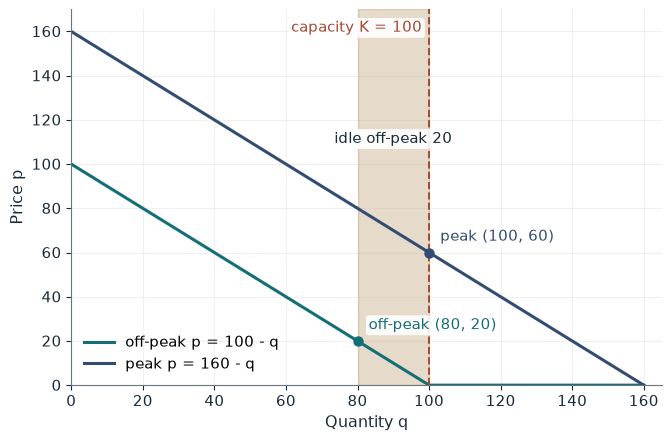

Off-peak price p_O      20
Peak price p_P          60
Off-peak quantity q_O   80
Peak quantity q_P       100
Capacity K              100
Idle off-peak capacity  20

Worked steps:
  1. p_O = 20
  2. p_P = 20 + 40 = 60
  3. q_O = 100 - 20 = 80
  4. q_P = 160 - 60 = 100
  5. K = 100
  6. Idle = 100 - 80 = 20

Only the peak constraint binds, so off-peak users pay operating cost, p_O = 20, and peak users also pay for capacity, p_P = 20 + 40 = 60. Then q_O = 100 - 20 = 80 and q_P = 160 - 60 = 100, so K = 100. Idle off-peak capacity is 100 - 80 = 20, so another off-peak unit triggers no investment.


In [2]:
show(peak_picture(capcost=40, tariff='efficient'))

Change one input, `capcost`, and hold the others at the book's values:

In [3]:
sweep(peak_picture, 'capcost', [20, 40, 60], {'tariff': 'efficient'}, ['Peak price p_P', 'Capacity K', 'Idle off-peak capacity'])

capcost | Peak price p_P | Capacity K | Idle off-peak capacity
20 | 40 | 120 | 40
40 | 60 | 100 | 20
60 | 80 | 80 | 0


The efficient tariff sells 80 off-peak and 100 at the peak, so K = 100 and 20 units sit idle off-peak. A uniform price of 40 (`tariff='uniform'`) shifts use to the peak and needs K = 120.

## 2. Natural monopoly by subadditivity: one network or two?

$$C(q)=100+2q,\qquad 0<q\leq100.$$

$$\sum_{j=1}^{m}(100+2q_j)=100m+2(100).$$

With congestion instead, $$C(q)=40+q+0.02q^2.$$

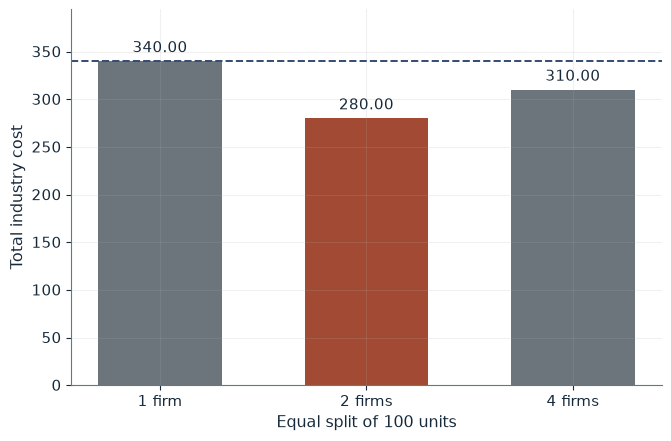

Output per firm           50.00
Cost per firm             140.00
Industry cost             280.00
One-firm cost             340.00
Difference from one firm  -60.00

Worked steps:
  1. q = 100 / 2 = 50.00
  2. Cost per firm = 40 + 50.00 + 0.02 x 50.00^2 = 40 + 50.00 + 50.00 = 140.00
  3. Industry = 2 x 140.00 = 280.00
  4. One firm = 340.00; difference -60.00

With C(q) = 40 + q + 0.02q^2 and 2 firms each serving 50.00, each firm costs 40 + 50.00 + 0.02 x 50.00^2 = 40 + 50.00 + 50.00 = 140.00, and the industry pays 2 x 140.00 = 280.00. Splitting saves 60.00 against one firm, so subadditivity fails at this split.


In [4]:
show(subadd_picture(tech='congestion', firms=2))

Change one input, `firms`, and hold the others at the book's values:

In [5]:
sweep(subadd_picture, 'firms', [1, 2, 4], {'tech': 'congestion'}, ['Industry cost', 'Difference from one firm'])

firms | Industry cost | Difference from one firm
1 | 340.00 | 0.00
2 | 280.00 | -60.00
4 | 310.00 | -30.00


With the fixed-cost technology one firm (300) beats any split; with congestion two firms cost 280, less than one firm's 340, so subadditivity fails. Four firms (310) duplicate too much fixed cost.

## 3. Ramsey-Boiteux pricing: fares that raise \$900

$$1{,}000(m_C+m_L)=900,\qquad m_C+m_L=0.90.$$

Inverse elasticity gives $m_C=0.72$ and $m_L=0.18$, and

$$|\Delta q_C|\approx0.5\left(\frac{0.72}{2}\right)1{,}000=180$$

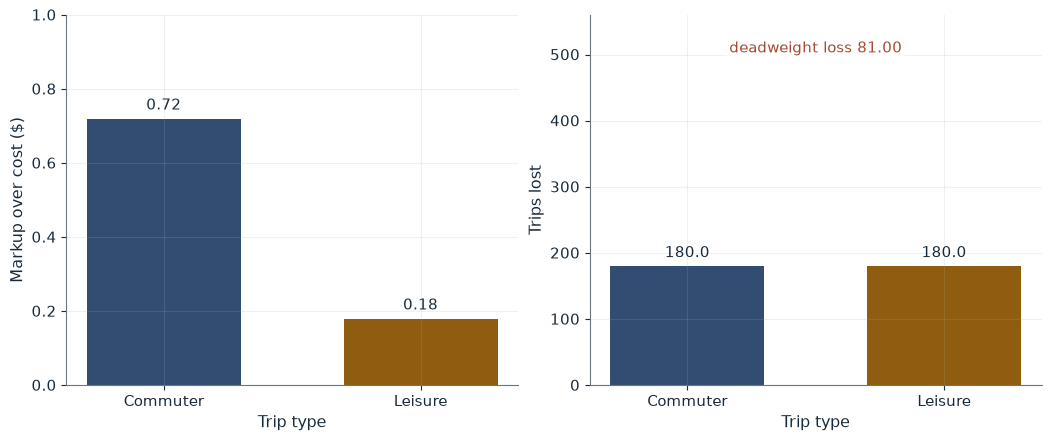

Commuter markup m_C  0.72
Leisure markup m_L   0.18
Commuter fare        $2.72
Leisure fare         $2.18
Commuter trips lost  180.0
Leisure trips lost   180.0
Deadweight loss      $81.00

Worked steps:
  1. m_C + m_L = 900 / 1,000 = 0.90
  2. m_C / m_L = 2 / 0.5 = 4: m_C = 0.72, m_L = 0.18
  3. Lost commuter trips = 0.5 x 0.360 x 1,000 = 180.0
  4. Lost leisure trips = 2 x 0.090 x 1,000 = 180.0
  5. DWL = 64.8000 + 16.2000 = 81.0000

Markups must sum to 900 / 1,000 = 0.90 and inverse elasticity sets m_C / m_L = 2 / 0.5 = 4, so m_C = 0.72 and m_L = 0.18. Lost trips are 0.5 x (0.72 / 2) x 1,000 = 180.0 and 2 x (0.18 / 2) x 1,000 = 180.0. Deadweight loss is 0.5 x 0.72 x 180.0 + 0.5 x 0.18 x 180.0 = 64.8000 + 16.2000 = 81.0000, about $81.00.


In [6]:
show(ramsey_picture(eps_c=0.5, scheme='ramsey'))

Change one input, `scheme`, and hold the others at the book's values:

In [7]:
sweep(ramsey_picture, 'scheme', ['ramsey', 'uniform'], {'eps_c': 0.5}, ['Commuter markup m_C', 'Leisure markup m_L', 'Deadweight loss'])

scheme | Commuter markup m_C | Leisure markup m_L | Deadweight loss
ramsey | 0.72 | 0.18 | $81.00
uniform | 0.45 | 0.45 | $126.56


Ramsey markups lose \$81 against \$126.56 for a uniform 0.45. When commuters become as elastic as leisure riders (`eps_c=2`) the two schemes coincide.

## 4. Price controls and rationing: the shortage and the queue

$$Q_D=120-2p,\qquad Q_S=3p.$$

Under a ceiling of 12 the surplus on the 36 units supplied is

$$\int_0^{36}\left(60-\frac{q}{2}-\frac{q}{3}\right)dq =\$1{,}620.$$

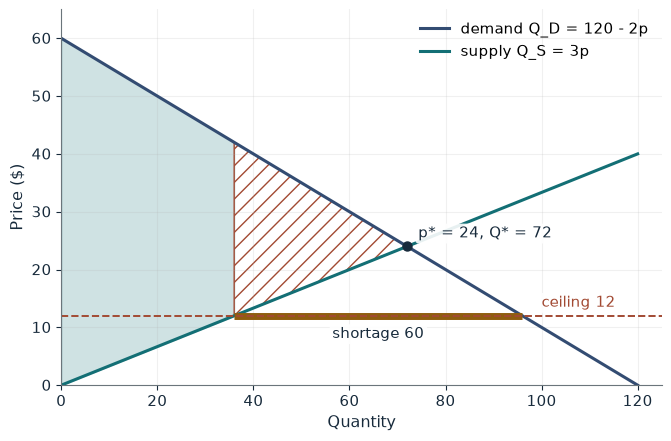

Quantity demanded             96
Quantity supplied             36
Shortage                      60
Marginal willingness to pay   $42
Surplus with best allocation  $1,620
Lost to the ceiling           $540
Queue and search cost         $300
Realized surplus              $1,320

Worked steps:
  1. Q_D = 120 - 2 x 12 = 96; Q_S = 3 x 12 = 36
  2. Shortage = 96 - 36 = 60
  3. p_D(36) = 60 - 36/2 = 42
  4. Surplus = 60 x 36 - (5/12) x 36^2 = 2,160 - 540 = 1,620
  5. Lost = 2,160 - 1,620 = 540
  6. Realized = 1,620 - 300 = 1,320

At the ceiling of 12, demand is 120 - 2 x 12 = 96 and supply 3 x 12 = 36, a shortage of 60. Buyers value the last unit at 60 - 36/2 = 42, so resale could carry a premium up to 42 - 12 = 30. Surplus on 36 units is 60 x 36 - (5/12) x 36^2 = 1,620, against 2,160 at Q* = 72, a loss of 540. Queuing and search worth $300 cut realized surplus to 1,620 - 300 = $1,320, $840 below the benchmark.


In [8]:
show(ceiling_picture(ceiling=12, queue=300))

Change one input, `ceiling`, and hold the others at the book's values:

In [9]:
sweep(ceiling_picture, 'ceiling', [12, 18, 24, 30], {'queue': 300}, ['Shortage', 'Surplus with best allocation', 'Realized surplus'])

ceiling | Shortage | Surplus with best allocation | Realized surplus
12 | 60 | $1,620 | $1,320
18 | 30 | $2,025 | $1,725
24 | 0 | $2,160 | $2,160
30 | 0 | $2,160 | $2,160


A ceiling of 12 cuts supply to 36 against demand of 96, loses \$540 of surplus, and a \$300 queue leaves \$1,320, \$840 below the benchmark. Ceilings at or above 24 do not bind.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

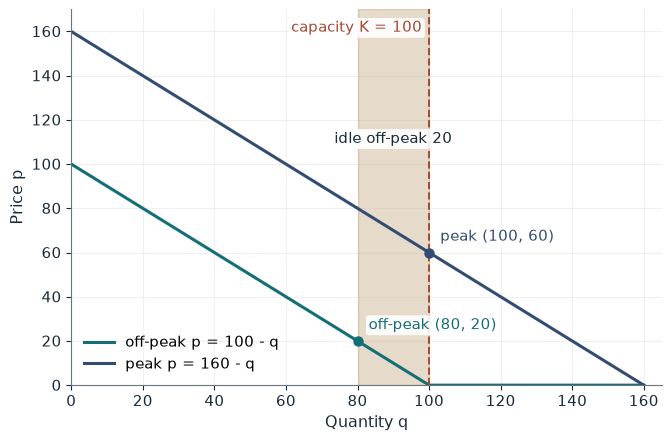

Off-peak price p_O      20
Peak price p_P          60
Off-peak quantity q_O   80
Peak quantity q_P       100
Capacity K              100
Idle off-peak capacity  20

Worked steps:
  1. p_O = 20
  2. p_P = 20 + 40 = 60
  3. q_O = 100 - 20 = 80
  4. q_P = 160 - 60 = 100
  5. K = 100
  6. Idle = 100 - 80 = 20

Only the peak constraint binds, so off-peak users pay operating cost, p_O = 20, and peak users also pay for capacity, p_P = 20 + 40 = 60. Then q_O = 100 - 20 = 80 and q_P = 160 - 60 = 100, so K = 100. Idle off-peak capacity is 100 - 80 = 20, so another off-peak unit triggers no investment.


In [10]:
show(peak_picture(capcost=40, tariff='efficient'))

## Practice

**1.** With capacity cost 20, how much capacity does the efficient tariff require?

<details><summary>Answer</summary>

p_P = 20 + 20 = 40, q_P = 160 - 40 = 120, so K = 120; off-peak q_O = 80 stays below it.

</details>

**2.** At commuter elasticity 1, what are the Ramsey markups?

<details><summary>Answer</summary>

m_C / m_L = 2 / 1 = 2 and m_C + m_L = 0.90, so m_C = 0.60 and m_L = 0.30.

</details>

**3.** At a ceiling of 18 with frictionless allocation, how much surplus is lost relative to 2,160?

<details><summary>Answer</summary>

Q_S = 54; surplus = 60 x 54 - (5/12) x 54^2 = 3,240 - 1,215 = 2,025; lost 2,160 - 2,025 = 135.

</details>